# ошибки yolo26n


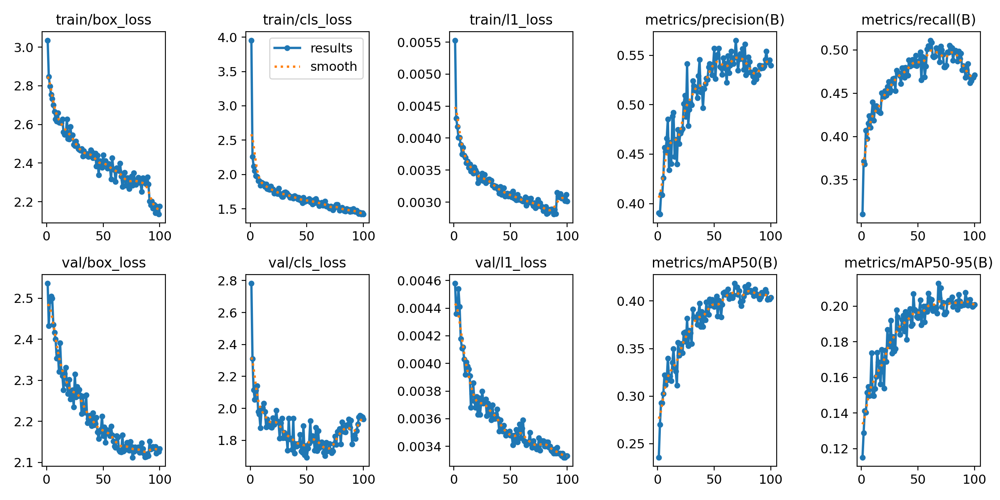

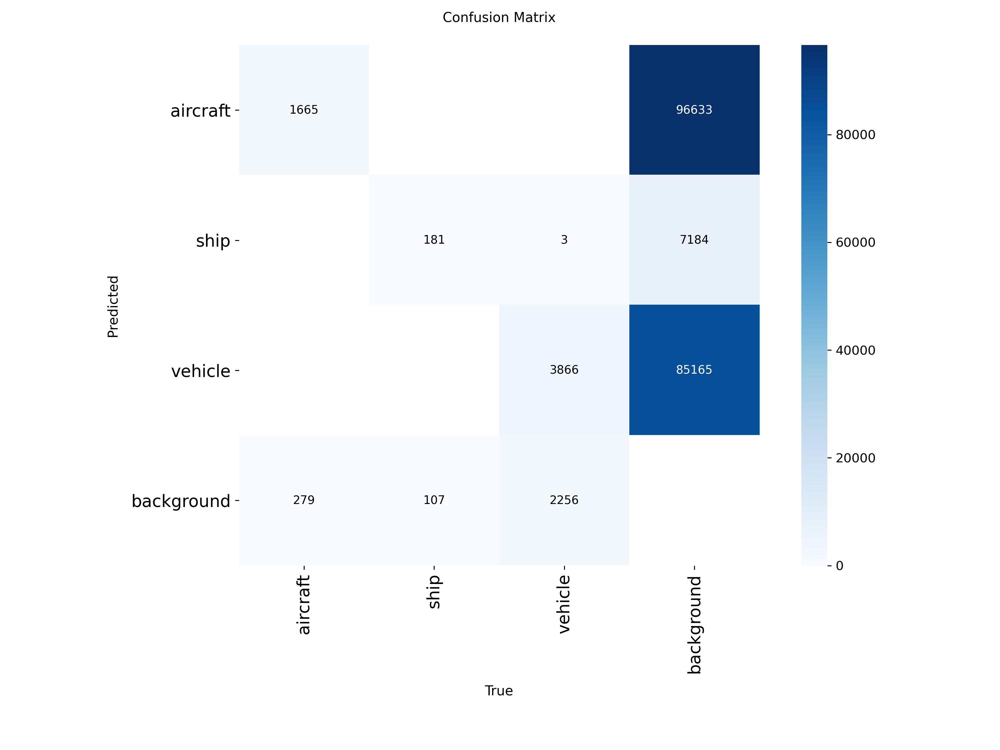

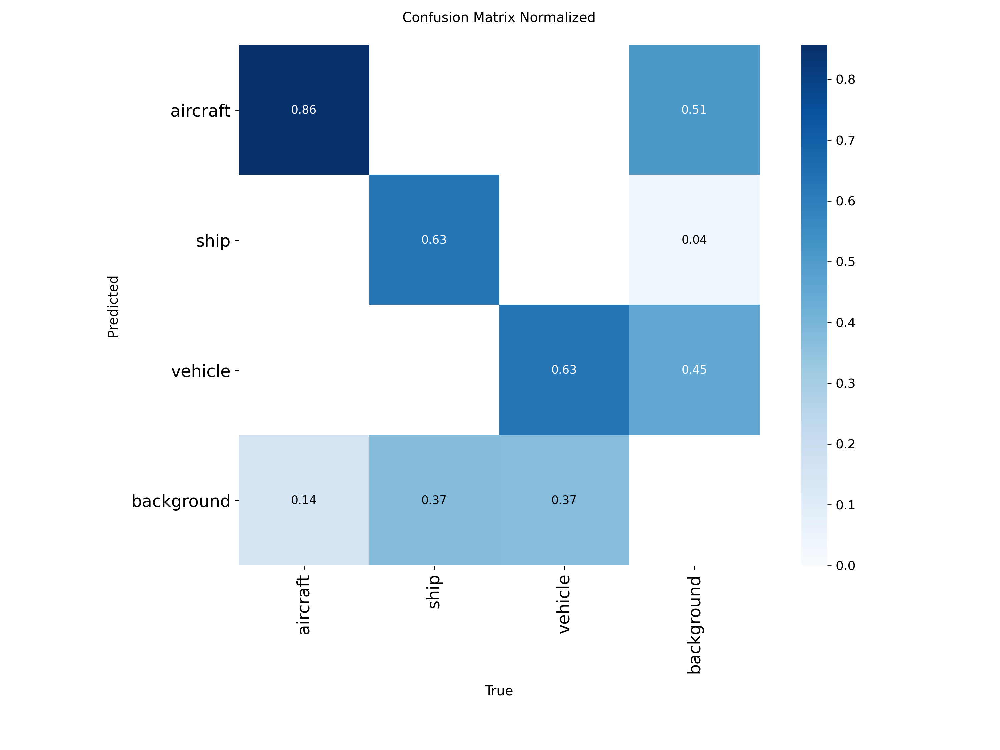

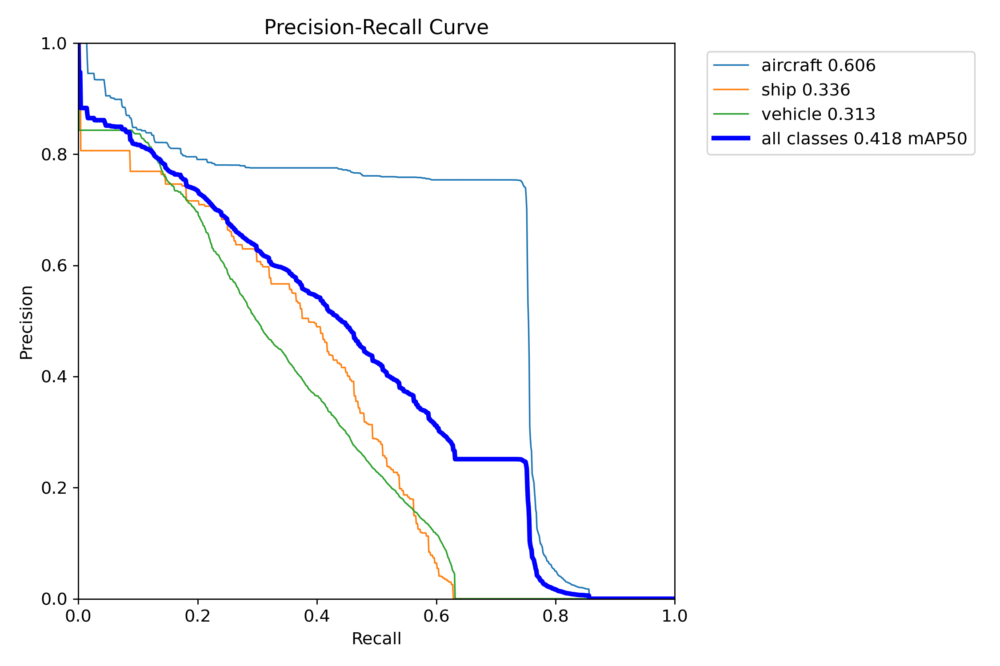

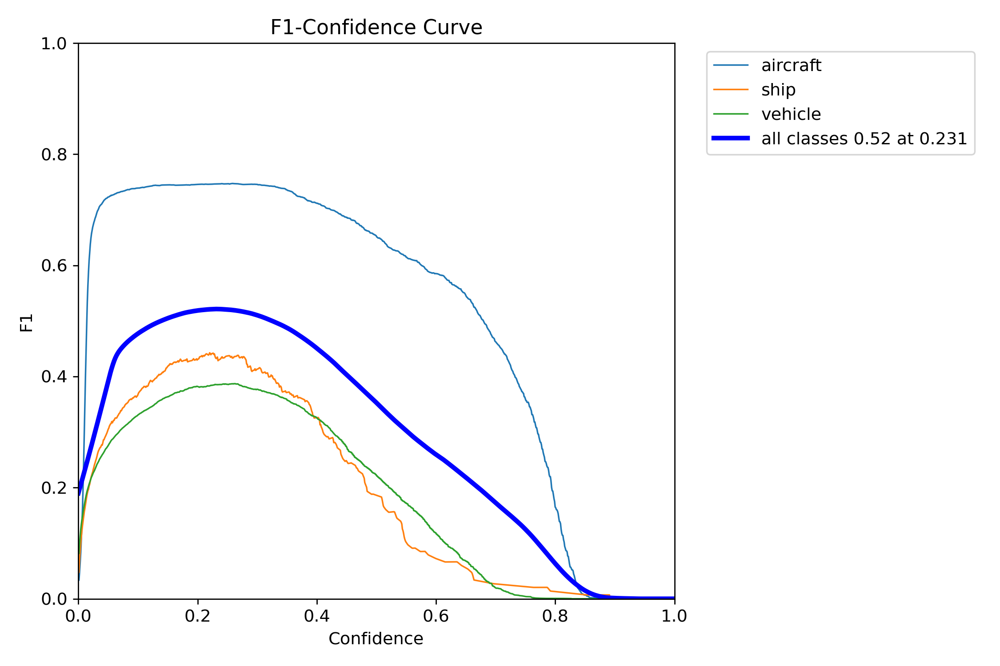

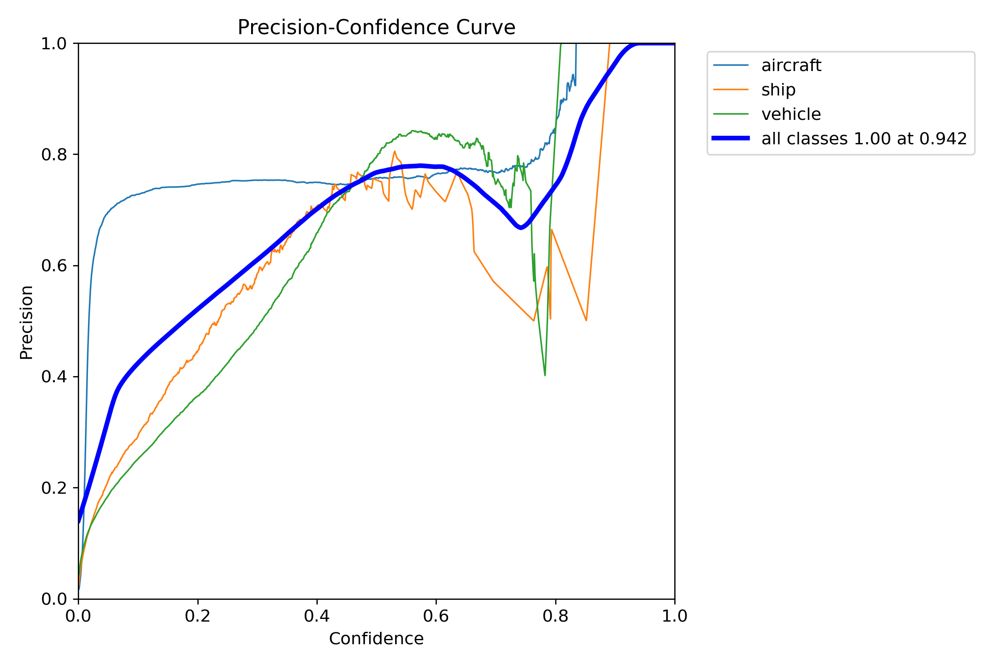

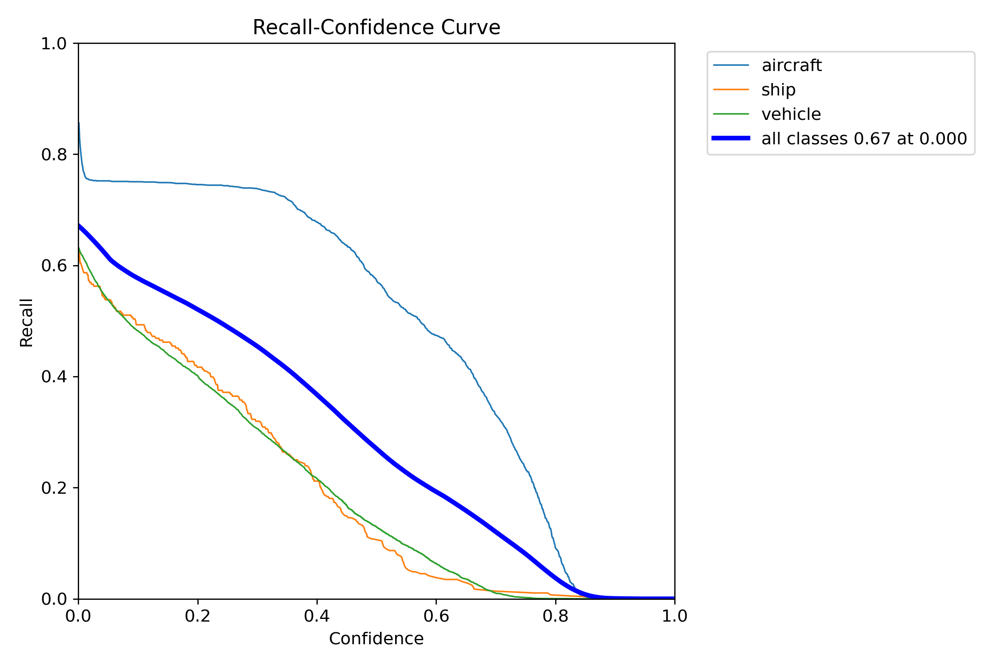

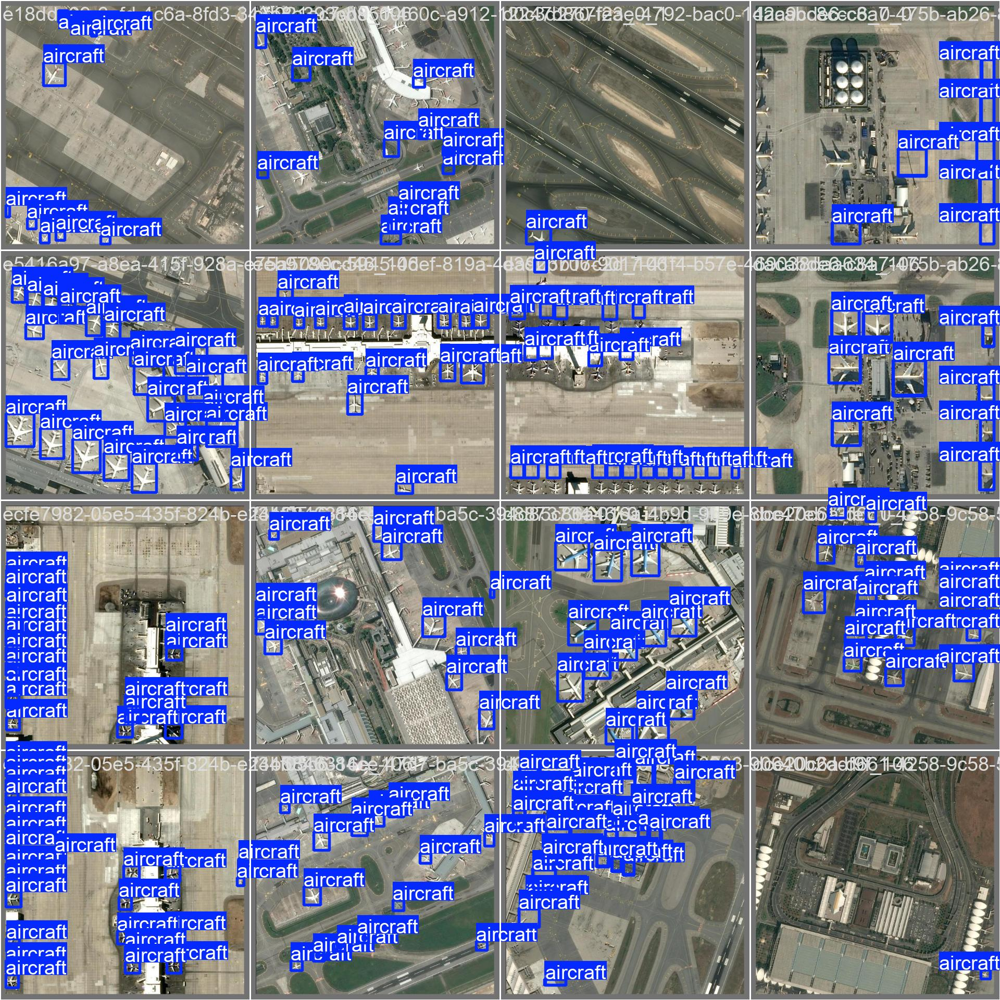

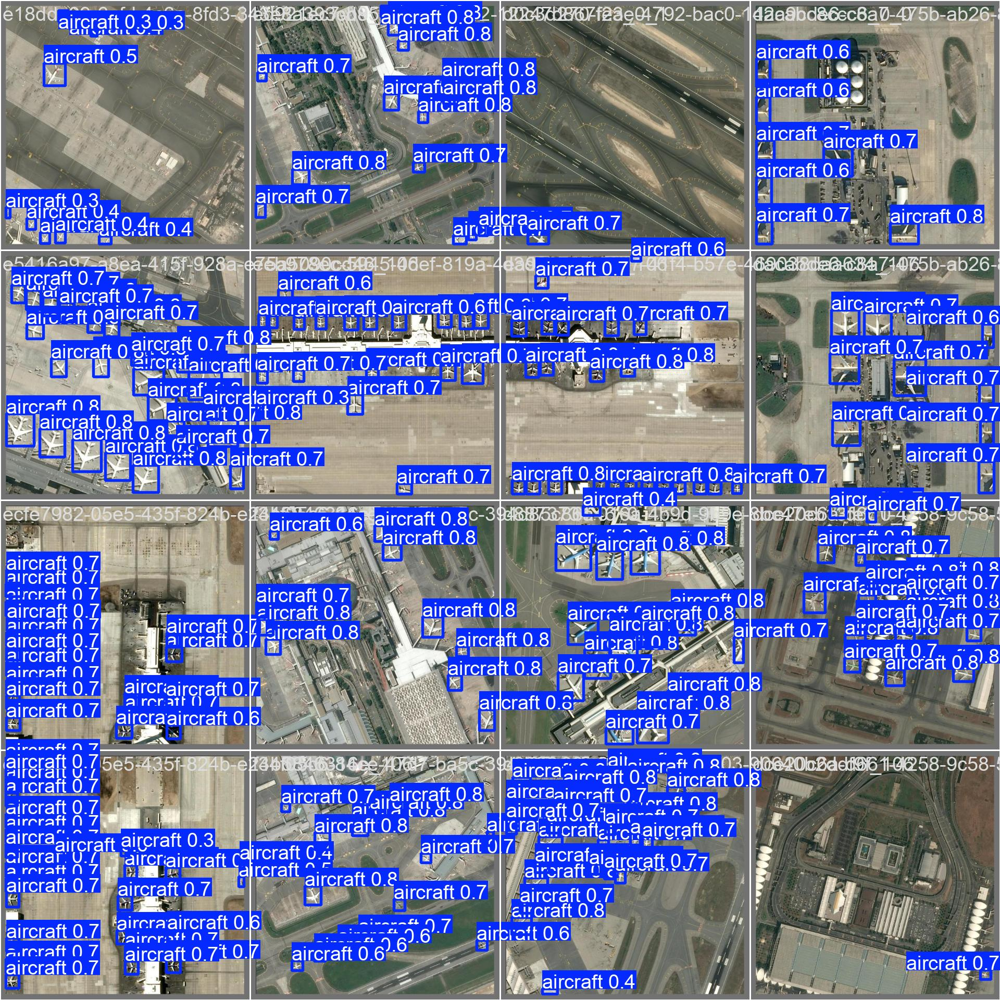

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
from IPython.display import Image, display

here = Path.cwd()
candidates = [here, here.parent, here / "SkyFusion_detection"]
root = next(p for p in candidates if (p / "sky").is_dir() and (p / "configs").is_dir())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

run = root / "runs" / "yolo26n"
for name in [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "val_batch0_labels.jpg",
    "val_batch0_pred.jpg",
]:
    path = run / name
    if not path.exists():
        print("нет", name)
        continue
    display(Image(filename=str(path)))



In [2]:
import json
import subprocess
import sys

weights = run / "weights" / "best.pt"
summary = run / "errors.json"
if not weights.exists():
    raise SystemExit(f"нет {weights}")

def _truncated(path):
    try:
        saved = json.loads(path.read_text())
    except Exception:
        return True
    return any(len(rows) < n for rows, n in zip(saved["fps"], saved["n_fp"]))

if not summary.exists() or summary.stat().st_mtime < weights.stat().st_mtime or _truncated(summary):
    print("fp/fn на valid")
    script = r"""
import json, os, sys
from pathlib import Path

os.environ["CUDA_VISIBLE_DEVICES"] = ""
root = Path(sys.argv[1])
sys.path.insert(0, str(root))
from sky.convert import label_dir_for, load_meta, read_label, split_dir
from ultralytics import YOLO

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    if inter <= 0:
        return 0.0
    area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
    return inter / (area_a + area_b - inter)

def remember(bucket, row, k=4):
    if len(bucket) < k or row[0] > min(item[0] for item in bucket):
        bucket.append(row)
        if len(bucket) > k:
            bucket.remove(min(bucket, key=lambda item: item[0]))

weights = Path(sys.argv[2])
meta = load_meta(root / "data" / "skyfusion.yaml")
names = list(meta["names"])
val_dir = split_dir(meta, "val")
labels = label_dir_for(val_dir)
model = YOLO(str(weights))
fps = {i: [] for i in range(len(names))}
fns = {i: [] for i in range(len(names))}
n_fp = {i: 0 for i in range(len(names))}
n_fn = {i: 0 for i in range(len(names))}
for res in model.predict(str(val_dir), imgsz=640, conf=0.25, iou=0.5, batch=1, workers=0, device="cpu", verbose=False, stream=True):
    path = Path(res.path)
    h, w = res.orig_shape
    gt = read_label(labels / (path.stem + ".txt"), w, h)
    preds = []
    if res.boxes is not None and len(res.boxes):
        xyxy = res.boxes.xyxy.detach().cpu().numpy()
        cls = res.boxes.cls.detach().cpu().numpy().astype(int)
        scores = res.boxes.conf.detach().cpu().numpy()
        preds = [(int(c), [float(x) for x in xyxy[i]], float(scores[i])) for i, c in enumerate(cls)]
    for c in range(len(names)):
        gt_c = [[float(x) for x in box] for cls_id, box in gt if cls_id == c]
        pr_c = [(box, score) for cls_id, box, score in preds if cls_id == c]
        used, hit_pr = set(), set()
        for pi in sorted(range(len(pr_c)), key=lambda i: -pr_c[i][1]):
            best_i, best_v = -1, 0.5
            for gi, gb in enumerate(gt_c):
                if gi in used:
                    continue
                value = iou(pr_c[pi][0], gb)
                if value >= best_v:
                    best_i, best_v = gi, value
            if best_i >= 0:
                used.add(best_i)
                hit_pr.add(pi)
        for i, (box, score) in enumerate(pr_c):
            if i not in hit_pr:
                n_fp[c] += 1
                fps[c].append((score, str(path), box, gt_c))
        for i, box in enumerate(gt_c):
            if i not in used:
                n_fn[c] += 1
                area = (box[2] - box[0]) * (box[3] - box[1])
                fns[c].append((area, str(path), box, [b for b, _ in pr_c]))
out = {
    "names": names,
    "n_fp": [n_fp[i] for i in range(len(names))],
    "n_fn": [n_fn[i] for i in range(len(names))],
    "fps": [fps[i] for i in range(len(names))],
    "fns": [fns[i] for i in range(len(names))],
}
Path(sys.argv[3]).write_text(json.dumps(out))
"""
    subprocess.check_call([sys.executable, "-c", script, str(root), str(weights), str(summary)])

data = json.loads(summary.read_text())
names = data["names"]

def as_rows(raw):
    return [(key, Path(path), box, others) for key, path, box, others in raw]

fps = [as_rows(rows) for rows in data["fps"]]
fns = [as_rows(rows) for rows in data["fns"]]
for i, name in enumerate(names):
    print(f"{name}: fp {data['n_fp'][i]}, fn {data['n_fn'][i]}")


fp/fn на valid
aircraft: fp 484, fn 499
ship: fp 81, fn 186
vehicle: fp 2288, fn 3906


In [3]:
import os

[x for x in os.listdir(root / "data" / "raw" / "valid") if "72fa2a" in x]

['72fa2a77-cf8e-44a2-9ab2-f11ca63b4b72_0_0_jpg.rf.61bdafb88b106ecaf5cba0b677c4743b.jpg']

In [4]:
import json

with open(root / "data" / "raw" / 'valid.json', "r") as f:
    data = json.load(f)
    print(data)

{'info': {'year': '2023', 'version': '1', 'description': 'Exported from roboflow.com', 'contributor': '', 'url': 'https://public.roboflow.com/object-detection/undefined', 'date_created': '2023-12-20T13:55:25+00:00'}, 'licenses': [{'id': 1, 'url': 'https://creativecommons.org/licenses/by/4.0/', 'name': 'CC BY 4.0'}], 'categories': [{'id': 1, 'name': 'Aircraft'}, {'id': 2, 'name': 'ship'}, {'id': 3, 'name': 'vehicle'}], 'images': [{'id': 0, 'license': 1, 'file_name': 'c98a544c-4206-4176-b480-35b8bdf5bb14_1060_1060_jpg.rf.02db2720c203b43d7ab3c1bdc4f62443.jpg', 'height': 640, 'width': 640, 'date_captured': '2023-12-20T13:55:25+00:00'}, {'id': 1, 'license': 1, 'file_name': 'eeb978ec-5945-4def-819a-4ea903b17c2d_1060_1060_jpg.rf.007db040c83d2ced4f32fbd19ae46202.jpg', 'height': 640, 'width': 640, 'date_captured': '2023-12-20T13:55:25+00:00'}, {'id': 2, 'license': 1, 'file_name': '15301_png_jpg.rf.041cb50f852322fd92c474b7c95c299b.jpg', 'height': 640, 'width': 640, 'date_captured': '2023-12-20T1

In [5]:
[image for image in data["images"] if image["file_name"] == "72fa2a77-cf8e-44a2-9ab2-f11ca63b4b72_0_0_jpg.rf.61bdafb88b106ecaf5cba0b677c4743b.jpg"]

[{'id': 176,
  'license': 1,
  'file_name': '72fa2a77-cf8e-44a2-9ab2-f11ca63b4b72_0_0_jpg.rf.61bdafb88b106ecaf5cba0b677c4743b.jpg',
  'height': 640,
  'width': 640,
  'date_captured': '2023-12-20T13:55:25+00:00'}]

In [6]:
bboxes = [annotation for annotation in data["annotations"] if annotation["image_id"] == 176]
print(bboxes)

[{'id': 3005, 'image_id': 176, 'category_id': 1, 'bbox': [114, 566, 88, 54], 'area': 4752, 'segmentation': [], 'iscrowd': 0}, {'id': 3006, 'image_id': 176, 'category_id': 1, 'bbox': [119, 349, 88, 76], 'area': 6688, 'segmentation': [], 'iscrowd': 0}, {'id': 3007, 'image_id': 176, 'category_id': 1, 'bbox': [126, 233, 76, 68], 'area': 5168, 'segmentation': [], 'iscrowd': 0}, {'id': 3008, 'image_id': 176, 'category_id': 1, 'bbox': [311, 127, 74, 72], 'area': 5328, 'segmentation': [], 'iscrowd': 0}, {'id': 3009, 'image_id': 176, 'category_id': 1, 'bbox': [313, 219, 86, 93], 'area': 7998, 'segmentation': [], 'iscrowd': 0}, {'id': 3010, 'image_id': 176, 'category_id': 1, 'bbox': [311, 341, 90, 88], 'area': 7920, 'segmentation': [], 'iscrowd': 0}, {'id': 3011, 'image_id': 176, 'category_id': 1, 'bbox': [314, 449, 78, 73], 'area': 5694, 'segmentation': [], 'iscrowd': 0}, {'id': 3012, 'image_id': 176, 'category_id': 1, 'bbox': [311, 559, 88, 61], 'area': 5368, 'segmentation': [], 'iscrowd': 0}]

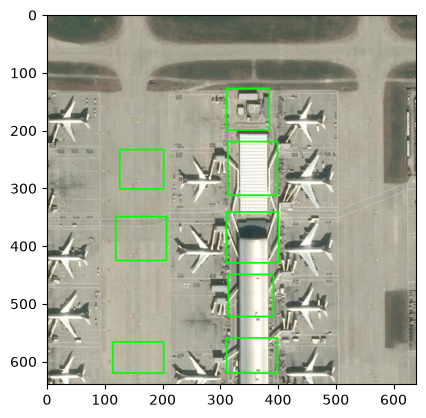

In [7]:
path = str(root / "data" / "raw" / "valid" / "72fa2a77-cf8e-44a2-9ab2-f11ca63b4b72_0_0_jpg.rf.61bdafb88b106ecaf5cba0b677c4743b.jpg")
im = cv2.imread(path)

for a in bboxes:
    x, y, w, h = a["bbox"]
    cv2.rectangle(im, (int(x), int(y)), (int(x + w), int(y + h)), (0, 255, 0), 2)
plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
plt.show()


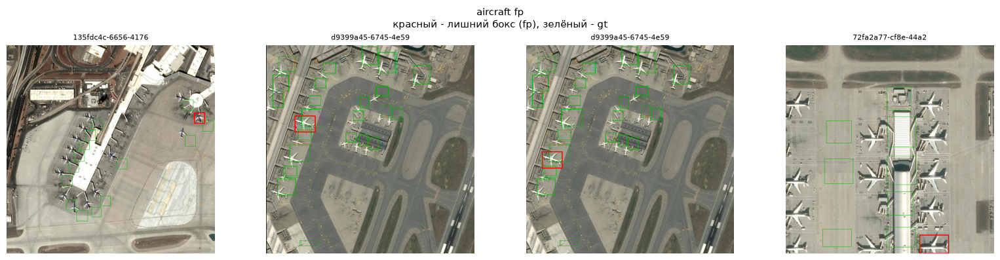

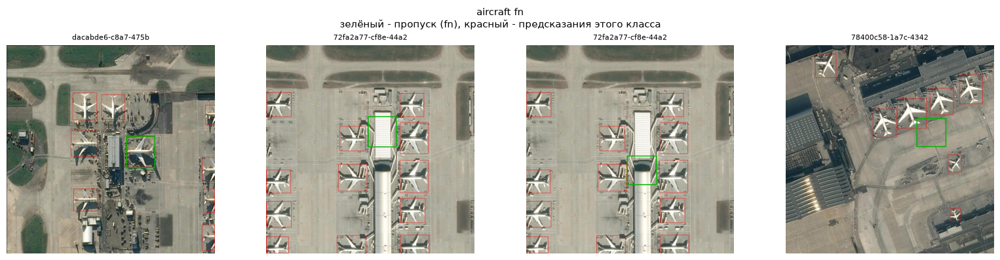

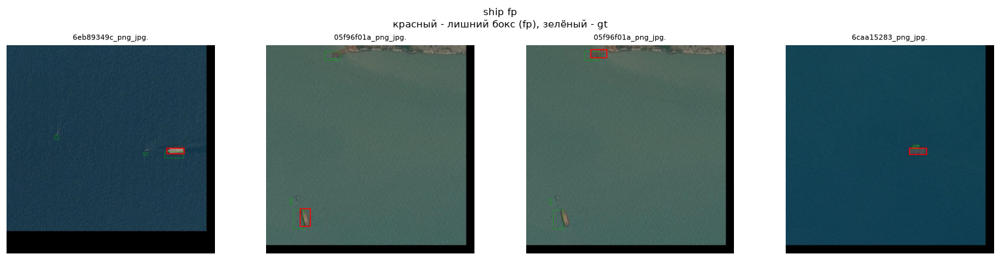

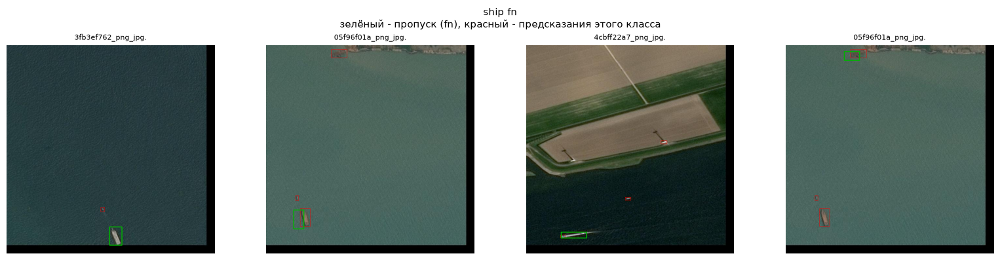

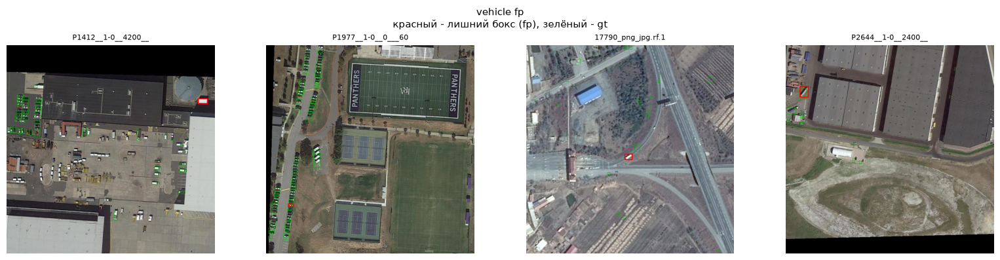

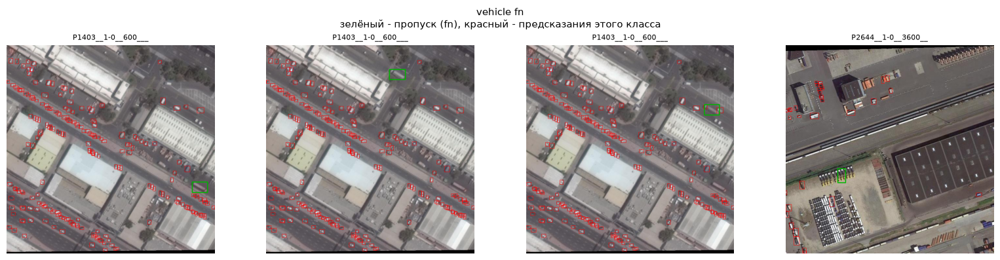

In [9]:
def show(rows, title, note, box_color, other_color):
    rows = rows[:4]
    if not rows:
        print(title, "пусто")
        return
    fig, axes = plt.subplots(1, len(rows), figsize=(4 * len(rows), 4))
    if len(rows) == 1:
        axes = [axes]
    for ax, row in zip(axes, rows):
        _, path, box, others = row
        im = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
        for b in others:
            x1, y1, x2, y2 = [int(v) for v in b]
            cv2.rectangle(im, (x1, y1), (x2, y2), other_color, 1)
        x1, y1, x2, y2 = [int(v) for v in box]
        cv2.rectangle(im, (x1, y1), (x2, y2), box_color, 2)
        ax.imshow(im)
        ax.set_title(path.name[:18], fontsize=8)
        ax.axis("off")
    fig.suptitle(f"{title}\n{note}", fontsize=11)
    fig.tight_layout()
    plt.show()


# fps сортируем по убыванию score (сначала самые уверенные ложные срабатывания)
# fns сортируем по убыванию area (сначала самые большие пропуски)
for c, name in enumerate(names):
    fp_rows = sorted(fps[c], key=lambda row: -row[0])
    fn_rows = sorted(fns[c], key=lambda row: -row[0])
    show(fp_rows, f"{name} fp", "красный - лишний бокс (fp), зелёный - gt", (255, 0, 0), (0, 180, 0))
    show(fn_rows, f"{name} fn", "зелёный - пропуск (fn), красный - предсказания этого класса", (0, 180, 0), (255, 0, 0))


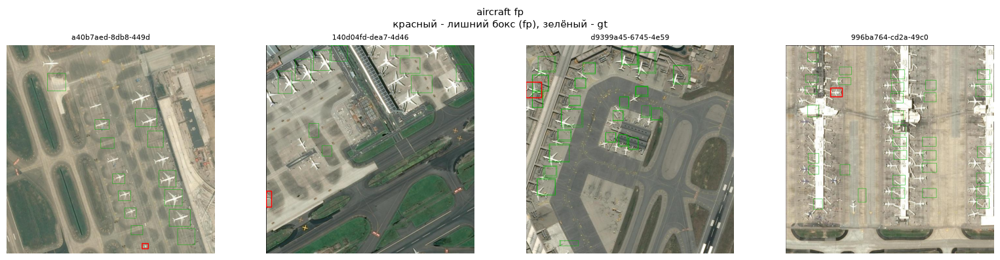

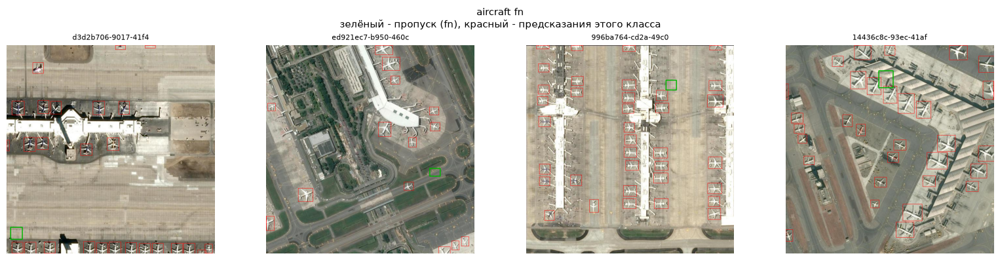

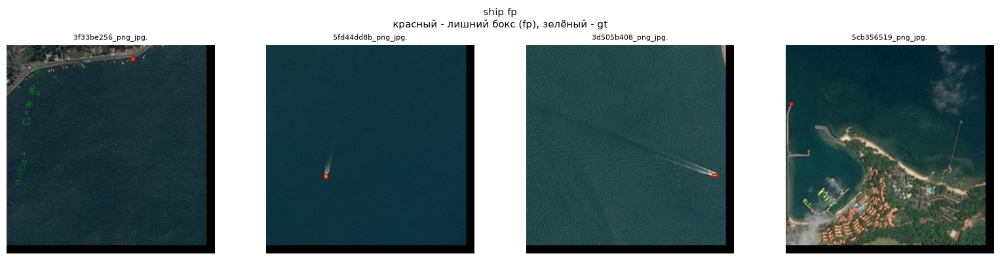

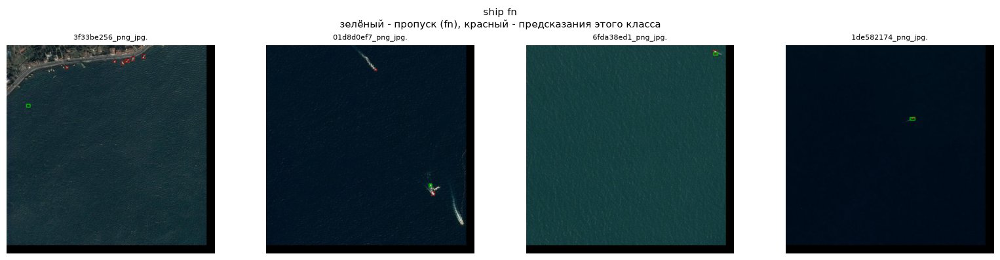

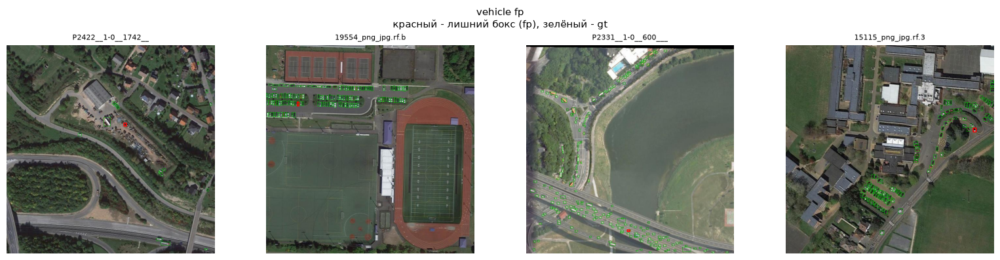

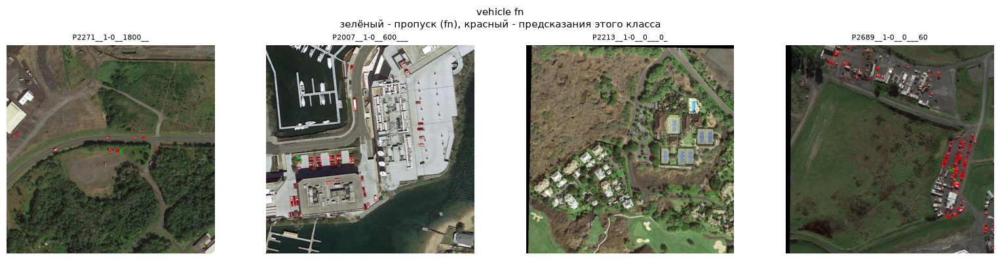

In [ ]:
# случайный порядок fp/fn
import random

random.seed(1)
for c, name in enumerate(names):
    fp_rows = fps[c]
    fn_rows = fns[c]
    random.shuffle(fp_rows)
    random.shuffle(fn_rows)
    show(fp_rows, f"{name} fp", "красный - лишний бокс (fp), зелёный - gt", (255, 0, 0), (0, 180, 0))
    show(fn_rows, f"{name} fn", "зелёный - пропуск (fn), красный - предсказания этого класса", (0, 180, 0), (255, 0, 0))
